In [145]:
# Librerías
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
from matplotlib import style
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import ConfusionMatrixDisplay
import statsmodels.api as sm
import statsmodels.formula.api as smf
from pathlib import Path

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    roc_curve
)


from sklearn.preprocessing import StandardScaler

from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from sklearn.linear_model import LogisticRegressionCV

# 1. Carga y preparación de datos

In [119]:
df = pd.read_csv('data/datos_preprocesados.csv')
df.head()

,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,...,Personas_Cargo,Fiador,Impago,Prima,Estudios_encoded,Estado_Civil_Divorciado,Estado_Civil_Soltero,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Jornada completa,Tipo_Jornada_Laboral_Tiempo parcial
0,KG9CT9,34,56572,73978,763,86,1,13.91,60,0.55,...,0,0,0,800.00,2,0,1,0,0,1
1,V5O0K9,37,68698,150000,824,162,2,10.53,24,0.37,...,0,0,0,580.00,2,0,0,0,1,0
2,YE5GD0,40,50000,7490,671,167,2,9.24,60,0.10,...,1,0,0,130.00,1,0,0,0,0,0
3,Q6HQ3D,38,63033,11801,649,196,1,7.63,48,0.10,...,1,0,0,168.08,1,0,1,0,0,1
4,XO8CO4,19,22301,40000,788,17,4,8.40,36,0.50,...,1,1,0,293.94,0,0,1,0,1,0


In [120]:
# Resultados del análisis financiero
finanzas = pd.read_csv(
    "data/clientes_clasificados_frances_aleman.csv"
)
finanzas.head()

,ID,Monto_Inicial,Ratio_Interes,Duracion,Ingresos,Esfuerzo_Inicial_Fr,Esfuerzo_Inicial_Al,Ahorro_Intereses_Al,Intereses_Totales_Fr,Sobreesfuerzo_Inicial_Al,Sistema_Recomendado,Ambos_Superan_Limite,Diferencia_Esfuerzo,Ahorro_Intereses_Pct
0,000AIY,53671,16.75,48,50294,36.785600,44.553312,1978.435520,20332.799374,325.557721,Francés,True,7.767711,9.730266
1,000OJE,40000,8.83,36,19018,80.060587,88.680899,232.600374,5677.767041,136.617582,Francés,True,8.620312,4.096688
2,000PLV,26187,8.43,48,69183,11.180782,12.653852,246.691329,4753.801366,84.926147,Alemán,False,1.473070,5.189349
3,000Q3U,78378,14.47,36,50507,64.071137,74.182384,1218.728598,18703.227523,425.573952,Francés,True,10.111247,6.516141
4,000TF1,3913,8.42,36,16000,9.253408,10.211300,20.695805,528.635813,12.771889,Alemán,False,0.957892,3.914946


In [121]:
columnas_financieras = [
    "ID",
    "Esfuerzo_Inicial_Fr",
    "Esfuerzo_Inicial_Al",
    "Ahorro_Intereses_Pct",
    "Sobreesfuerzo_Inicial_Al",
    "Sistema_Recomendado",
    "Ambos_Superan_Limite"
]

In [122]:
# describe de varibales numéricas contínuas
df[['Ratio_Interes', 'Duracion', 'Ratio_Deuda_Ingresos', 'Prima', 'Ingresos', 'Monto_Inicial', 'Scoring_Crediticio', 'Meses_Empleo', 'Num_Creditos']].describe()

,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,Prima,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos
count,178606.000000,178606.000000,178606.000000,178606.000000,178606.000000,178606.000000,178606.000000,178606.000000,178606.000000
mean,10.676211,37.255523,0.321933,386.809055,41509.970740,45190.765937,692.053285,212.770601,2.001025
std,3.809254,14.166838,0.181164,267.648386,16036.504202,46648.083692,87.828224,150.688070,1.001298
min,2.010000,12.000000,0.100000,10.000000,16000.000000,3000.000000,398.000000,0.000000,1.000000
25%,7.960000,24.000000,0.140000,138.880000,30484.250000,15126.000000,635.000000,70.000000,1.000000
50%,10.590000,36.000000,0.290000,340.095000,39090.500000,40000.000000,704.000000,208.000000,2.000000
75%,13.270000,48.000000,0.550000,621.670000,50096.750000,47626.500000,761.000000,336.000000,3.000000
max,24.440000,60.000000,0.550000,800.000000,120000.000000,400000.000000,845.000000,639.000000,4.000000


In [123]:
df = df.merge(
    finanzas[columnas_financieras],
    on="ID",
    how="left",
    validate="one_to_one"
)

df.head()

,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,...,Estado_Civil_Soltero,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Jornada completa,Tipo_Jornada_Laboral_Tiempo parcial,Esfuerzo_Inicial_Fr,Esfuerzo_Inicial_Al,Ahorro_Intereses_Pct,Sobreesfuerzo_Inicial_Al,Sistema_Recomendado,Ambos_Superan_Limite
0,KG9CT9,34,56572,73978,763,86,1,13.91,60,0.55,...,1,0,0,1,36.439698,44.343385,10.107178,372.606139,Francés,True
1,V5O0K9,37,68698,150000,824,162,2,10.53,24,0.37,...,0,0,1,0,121.549207,132.165420,3.238250,607.760466,Francés,True
2,YE5GD0,40,50000,7490,671,167,2,9.24,60,0.10,...,0,0,0,0,3.752495,4.380152,6.990729,26.152370,Alemán,False
3,Q6HQ3D,38,63033,11801,649,196,1,7.63,48,0.10,...,1,0,0,1,5.445751,6.108969,4.723142,34.837147,Alemán,False
4,XO8CO4,19,22301,40000,788,17,4,8.40,36,0.50,...,1,0,1,0,67.845326,74.854640,3.906059,130.262266,Francés,True


In [124]:
print("Dimensiones:", df.shape)

print("\nValores ausentes en variables financieras:")
print(df[columnas_financieras[1:]].isna().sum())

Dimensiones: (178606, 27)

Valores ausentes en variables financieras:
Esfuerzo_Inicial_Fr         0
Esfuerzo_Inicial_Al         0
Ahorro_Intereses_Pct        0
Sobreesfuerzo_Inicial_Al    0
Sistema_Recomendado         0
Ambos_Superan_Limite        0
dtype: int64


In [125]:
# Convertir el booleano a 0 y 1
df["Ambos_Superan_Limite"] = (
    df["Ambos_Superan_Limite"].astype(int)
)

In [126]:
# Para que solo aparezca el esfuerzo del sistema elegido
df["Esfuerzo_Sistema_Elegido"] = np.where(
    df["Sistema_Recomendado"] == "Alemán",
    df["Esfuerzo_Inicial_Al"],
    df["Esfuerzo_Inicial_Fr"]
)

In [127]:
#Transformar las variables financieras
df = pd.get_dummies(
    df,
    columns=["Sistema_Recomendado"],
    drop_first=True,
    dtype=int
)

In [128]:
resumen = pd.DataFrame({
        "Frecuencia": df['Impago'].value_counts(),
        "Porcentaje": (
            df['Impago']
            .value_counts(normalize=True)
            .mul(100)
            .round(2)
        )
    })
resumen

,Frecuencia,Porcentaje
Impago,,
0,157832,88.37
1,20774,11.63


El 88.37% de los clientes han pagado y el 11.63% no. Un modelo de clasificación que sea útil debe de ser capaz de predecir correctamente un porcentaje de observaciones por encima del porcentaje de la clase mayoritaria. En este caso, el umbral de referencia que se tiene que superar es del 88.37%.

# 2. División train/test y escalado

Antes de ajustar la regresión logística se excluyen algunas columnas que no deben utilizarse directamente como variables predictoras:
- Impago: es la variable objetivo que el modelo debe predecir. Por tanto, se guarda por separado en y.
- ID: es únicamente un identificador de cada cliente. No representa una característica económica o financiera y podría introducir relaciones artificiales.
- Prima: se excluye porque el objetivo final es calcular la prima a partir del riesgo de impago estimado. Utilizarla para predecir el impago produciría una relación circular y podría generar fuga de información.
- Esfuerzo_Inicial_Fr y Esfuerzo_Inicial_Al: representan el esfuerzo de cuota bajo los dos sistemas posibles. Se sustituyen por Esfuerzo_Sistema_Elegido, que recoge únicamente el esfuerzo correspondiente al sistema recomendado para cada cliente. De este modo se evita introducir información redundante.

In [129]:
columnas_excluir = [
    "Impago",
    "ID",
    "Prima",
    "Esfuerzo_Inicial_Fr",
    "Esfuerzo_Inicial_Al"
]

X = df.drop(columns=columnas_excluir)
y = df["Impago"]

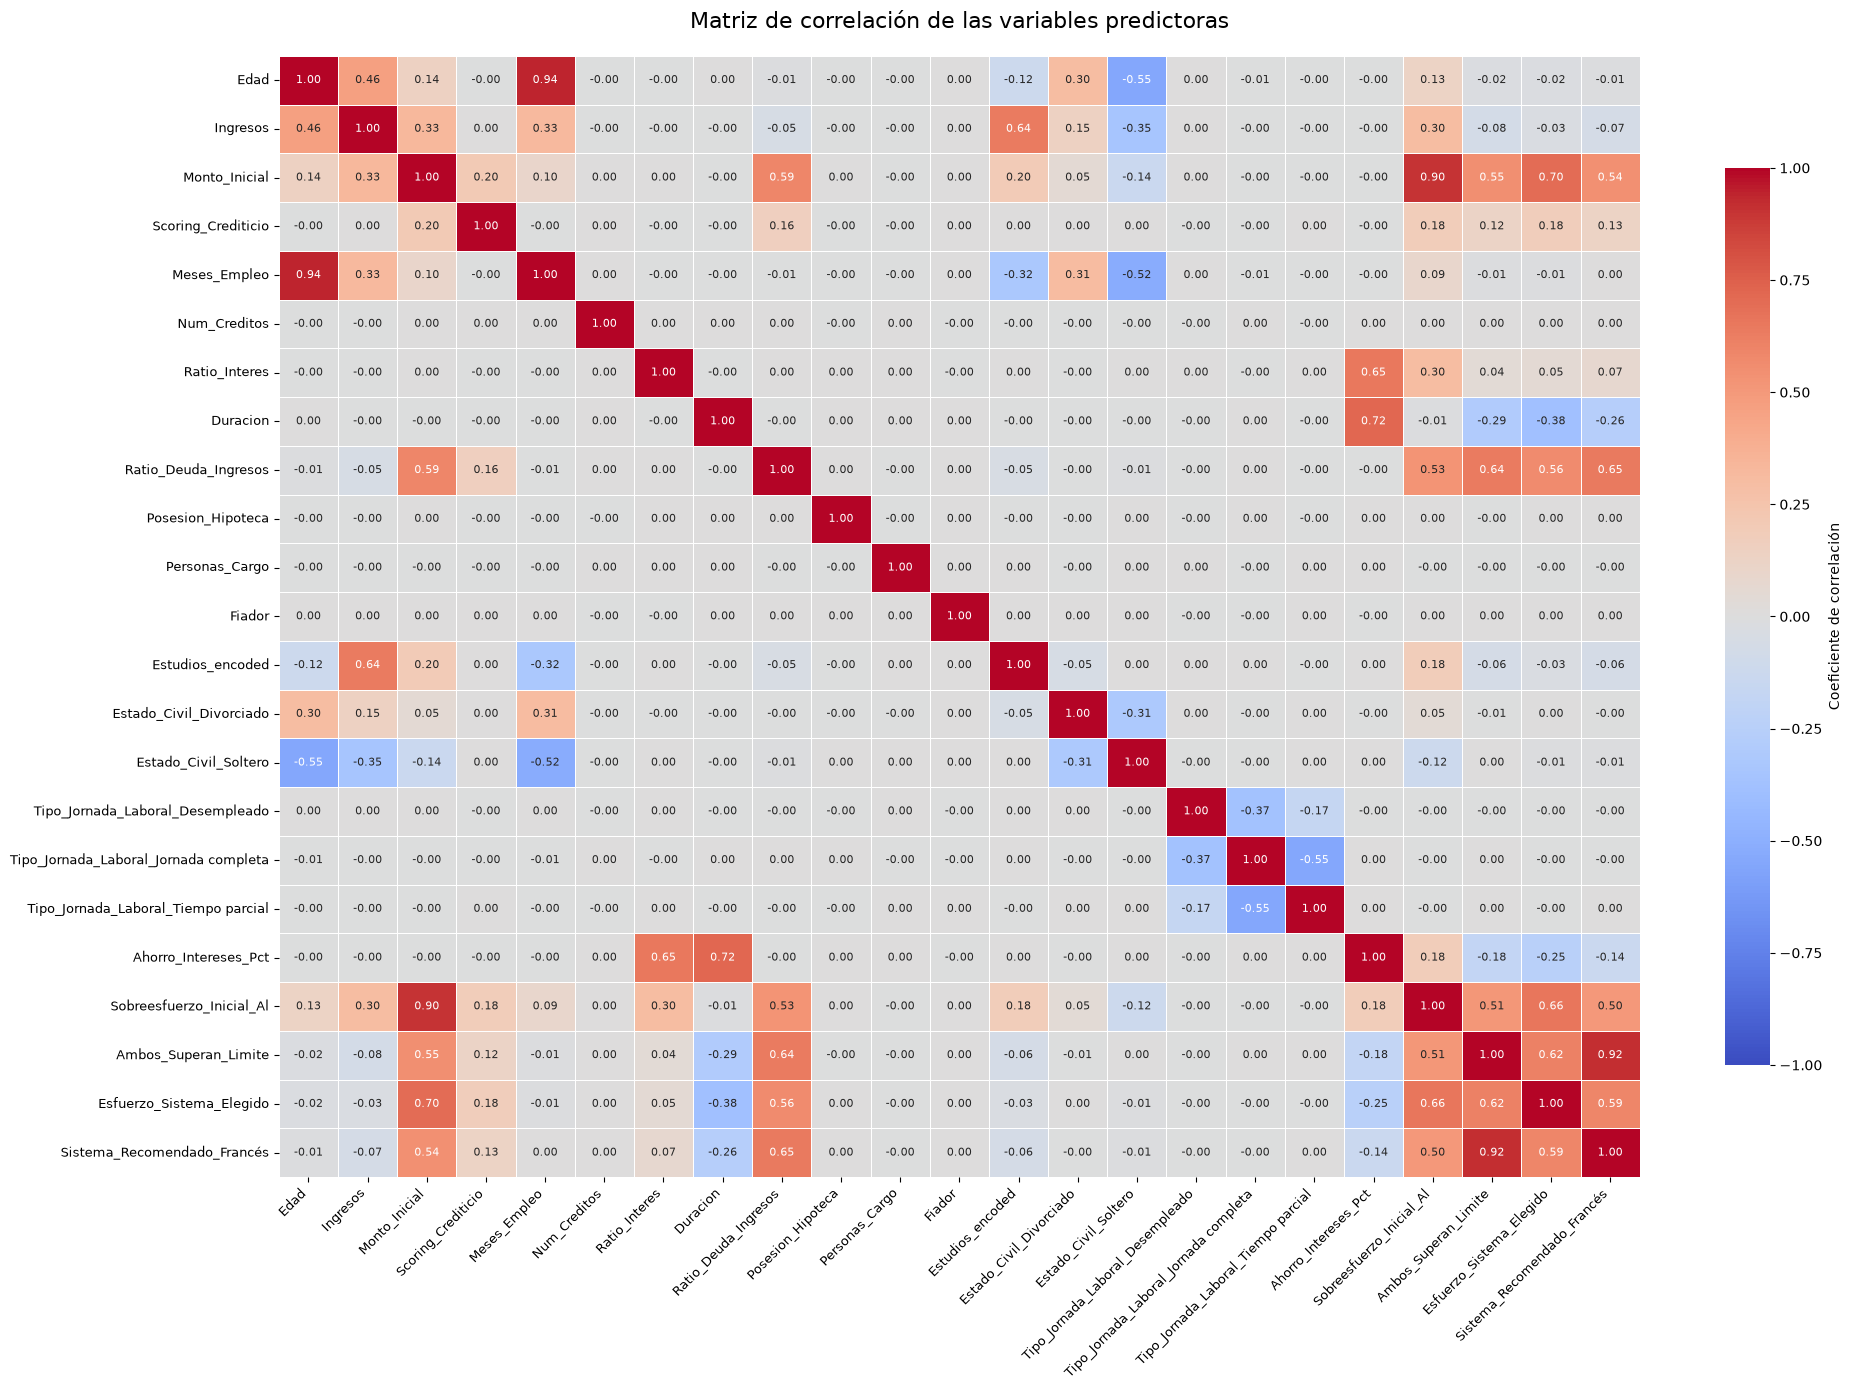

In [130]:
# Matriz de correlación de las variables que realmente entran al modelo
correlacion = X.corr()

plt.figure(figsize=(20, 14))

sns.heatmap(
    correlacion,
    annot=True,          # Mostrar los valores
    fmt=".2f",           # Dos decimales
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    linecolor="white",
    annot_kws={"size": 8},
    cbar_kws={
        "label": "Coeficiente de correlación",
        "shrink": 0.8
    }
)

plt.title(
    "Matriz de correlación de las variables predictoras",
    fontsize=16,
    pad=20
)

plt.xticks(
    rotation=45,
    ha="right",
    fontsize=9
)

plt.yticks(
    rotation=0,
    fontsize=9
)

plt.tight_layout()
plt.show()

In [131]:
columnas_excluir = [
    "Impago",
    "ID",
    "Prima",
    "Esfuerzo_Inicial_Fr",
    "Esfuerzo_Inicial_Al",
    "Edad",
    "Sobreesfuerzo_Inicial_Al",
    "Ambos_Superan_Limite"
]

X = df.drop(columns=columnas_excluir)
y = df["Impago"]

Se eliminaron las variables con correlaciones superiores a 0,90 para reducir la multicolinealidad. Se mantuvo Meses_Empleo frente a Edad por su mayor interpretación crediticia, Monto_Inicial frente a Sobreesfuerzo_Inicial_Al por ser una variable original, y Sistema_Recomendado_Francés frente a Ambos_Superan_Limite para conservar explícitamente el sistema de amortización asignado.

In [132]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    train_size=0.8,
    random_state=42,
    shuffle=True,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Realizamos predicciones probabilísticas:

- Con .predict_proba() se obtiene, para cada observación, la probabilidad predicha de pertenecer a cada una de las dos clases.

- Con .predict() se obtiene, para cada observación, la clasificación predicha por el modelo. Esta clasificación se corresponde con la clase con mayor probabilidad.


In [ ]:
def evaluar_modelo(modelo, X_test, y_test, nombre_modelo="Modelo"):
    
    # Predicción final con umbral 0.5
    prediccion = modelo.predict(X_test)
    
    # Probabilidad de pertenecer a la clase Impago = 1
    probabilidad = modelo.predict_proba(X_test)[:, 1]

    # Métricas principales
    print(f"RESULTADOS: {nombre_modelo}")

    print("\nCantidad de predicciones:")
    print(pd.Series(prediccion).value_counts())

    print("\nInforme de clasificación:")
    print(classification_report(y_test, prediccion))

      # Matriz de confusión gráfica
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        prediccion,
        display_labels=["No impago", "Impago"],
        cmap="Blues",
        values_format="d"
    )

    plt.title(
        f"Matriz de confusión - {nombre_modelo}"
    )
    plt.show()

    roc_auc = roc_auc_score(y_test, probabilidad)
    pr_auc = average_precision_score(y_test, probabilidad)

    print("ROC-AUC:", round(roc_auc, 3))
    print("PR-AUC:", round(pr_auc, 3))

    # Curva Precision-Recall
    precision, recall, umbrales_pr = precision_recall_curve(
        y_test,
        probabilidad
    )

    tabla_umbrales_pr = pd.DataFrame({
        "Precision": precision[:-1],
        "Recall": recall[:-1],
        "Umbral": umbrales_pr
    })

    # Curva ROC
    fpr, tpr, umbrales_roc = roc_curve(
        y_test,
        probabilidad
    )

    tabla_umbrales_roc = pd.DataFrame({
        "TPR_Recall": tpr,
        "FPR": fpr,
        "Umbral": umbrales_roc
    })

    # Representación de ambas curvas
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Curva Precision-Recall
    axes[0].plot(
        recall,
        precision,
        color="darkorange",
        label=f"PR-AUC = {pr_auc:.3f}"
    )

    # Nivel de referencia: porcentaje de impagos
    proporcion_impagos = y_test.mean()

    axes[0].axhline(
        proporcion_impagos,
        color="grey",
        linestyle="--",
        label=f"Referencia = {proporcion_impagos:.3f}"
    )

    axes[0].set_xlabel("Recall")
    axes[0].set_ylabel("Precision")
    axes[0].set_title(
        f"Curva Precision-Recall — {nombre_modelo}"
    )
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    # Curva ROC
    axes[1].plot(
        fpr,
        tpr,
        color="steelblue",
        label=f"ROC-AUC = {roc_auc:.3f}"
    )

    axes[1].plot(
        [0, 1],
        [0, 1],
        color="grey",
        linestyle="--",
        label="Clasificación aleatoria"
    )

    axes[1].set_xlabel("Ratio de falsos positivos")
    axes[1].set_ylabel("Ratio de verdaderos positivos")
    axes[1].set_title(
        f"Curva ROC — {nombre_modelo}"
    )
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    return tabla_umbrales_pr, tabla_umbrales_roc

# 3. Análisis estadístico con statsmodels

In [134]:
# Recuperamos los nombres de las variables después del escalado
X_train_scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

# Añadimos la constante
X_train_stats = sm.add_constant(X_train_scaled_df)

# Ajustamos la regresión logística
modelo_stats = sm.Logit(
    y_train,
    X_train_stats
).fit()

print(modelo_stats.summary())

Optimization terminated successfully.
         Current function value: 0.335932
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:                 Impago   No. Observations:               142884
Model:                          Logit   Df Residuals:                   142863
Method:                           MLE   Df Model:                           20
Date:                Wed, 14 Oct 2026   Pseudo R-squ.:                 0.06558
Time:                        16:06:23   Log-Likelihood:                -47999.
converged:                       True   LL-Null:                       -51368.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                            coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------
const                                    -2.2141      

In [135]:
import numpy as np

resultados_stats = pd.DataFrame({
    'Coeficiente': modelo_stats.params,
    'Odds_ratio': np.exp(modelo_stats.params),
    'P_valor': modelo_stats.pvalues
})

resultados_stats['Significativa_5%'] = (
    resultados_stats['P_valor'] < 0.05
)

resultados_stats

,Coeficiente,Odds_ratio,P_valor,Significativa_5%
const,-2.214119,0.109250,0.000000e+00,True
Ingresos,-0.002286,0.997717,9.005255e-01,False
Monto_Inicial,-0.041089,0.959743,2.610174e-02,True
Scoring_Crediticio,-0.101435,0.903540,4.985748e-33,True
Meses_Empleo,-0.575006,0.562701,5.646205e-283,True
Num_Creditos,-0.001818,0.998184,8.300639e-01,False
Ratio_Interes,0.386523,1.471854,7.253669e-52,True
Duracion,-0.047132,0.953962,1.295841e-01,False
Ratio_Deuda_Ingresos,0.019489,1.019680,1.272313e-01,False
Posesion_Hipoteca,-0.009611,0.990435,2.572195e-01,False


# 4. Predicción con sklearn

## 1. class_weight='balanced'

In [136]:
modelo_class_weight = LogisticRegression(
    class_weight='balanced',
    max_iter=2000,
    random_state=42
)

modelo_class_weight.fit(X_train_scaled, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

RESULTADOS: Class Weight

Cantidad de predicciones:
0    21153
1    14569
Name: count, dtype: int64

Matriz de confusión:
[[19704 11863]
 [ 1449  2706]]

Informe de clasificación:
              precision    recall  f1-score   support

           0       0.93      0.62      0.75     31567
           1       0.19      0.65      0.29      4155

    accuracy                           0.63     35722
   macro avg       0.56      0.64      0.52     35722
weighted avg       0.84      0.63      0.69     35722



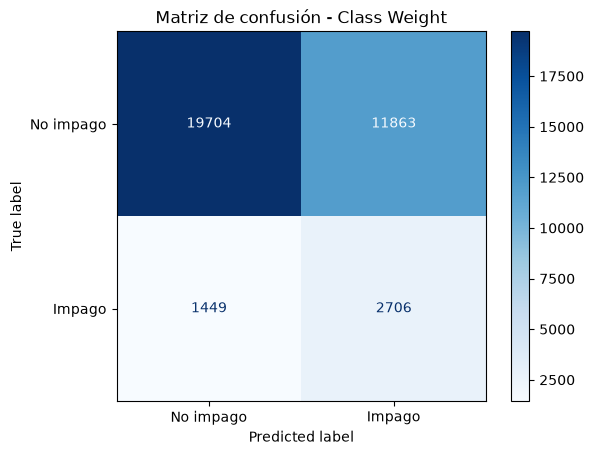

ROC-AUC: 0.688
PR-AUC: 0.223


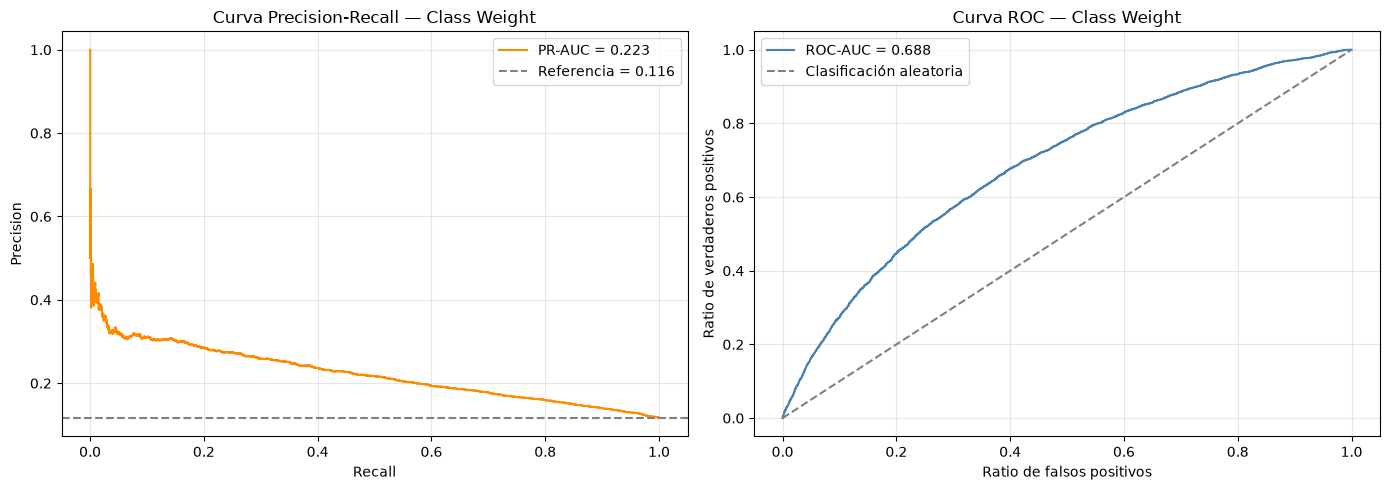

In [137]:
tabla_pr_class, tabla_roc_class = evaluar_modelo(
    modelo_class_weight,
    X_test_scaled,
    y_test,
    nombre_modelo="Class Weight"
)

## 2. RandomOverSampler

Oversampler es una técnica de balanceado, duplica aleatoriamente observaciones de impago hasta igualar las dos clases

In [138]:
oversampler = RandomOverSampler(random_state=42)

X_train_over, y_train_over = oversampler.fit_resample(
    X_train_scaled,
    y_train
)

print("Distribución original:")
print(pd.Series(y_train).value_counts())

print("\nDistribución después del oversampling:")
print(pd.Series(y_train_over).value_counts())

Distribución original:
Impago
0    126265
1     16619
Name: count, dtype: int64

Distribución después del oversampling:
Impago
0    126265
1    126265
Name: count, dtype: int64


In [139]:
modelo_over = LogisticRegression(
    max_iter=2000,
    random_state=42
)

modelo_over.fit(X_train_over, y_train_over)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

RESULTADOS: Oversampling

Cantidad de predicciones:
0    21211
1    14511
Name: count, dtype: int64

Matriz de confusión:
[[19748 11819]
 [ 1463  2692]]

Informe de clasificación:
              precision    recall  f1-score   support

           0       0.93      0.63      0.75     31567
           1       0.19      0.65      0.29      4155

    accuracy                           0.63     35722
   macro avg       0.56      0.64      0.52     35722
weighted avg       0.84      0.63      0.69     35722



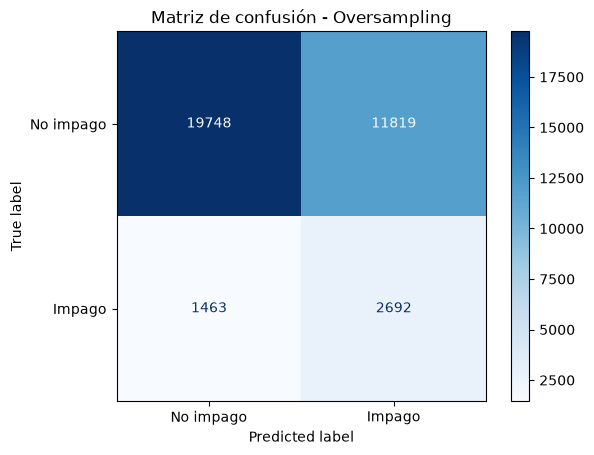

ROC-AUC: 0.688
PR-AUC: 0.223


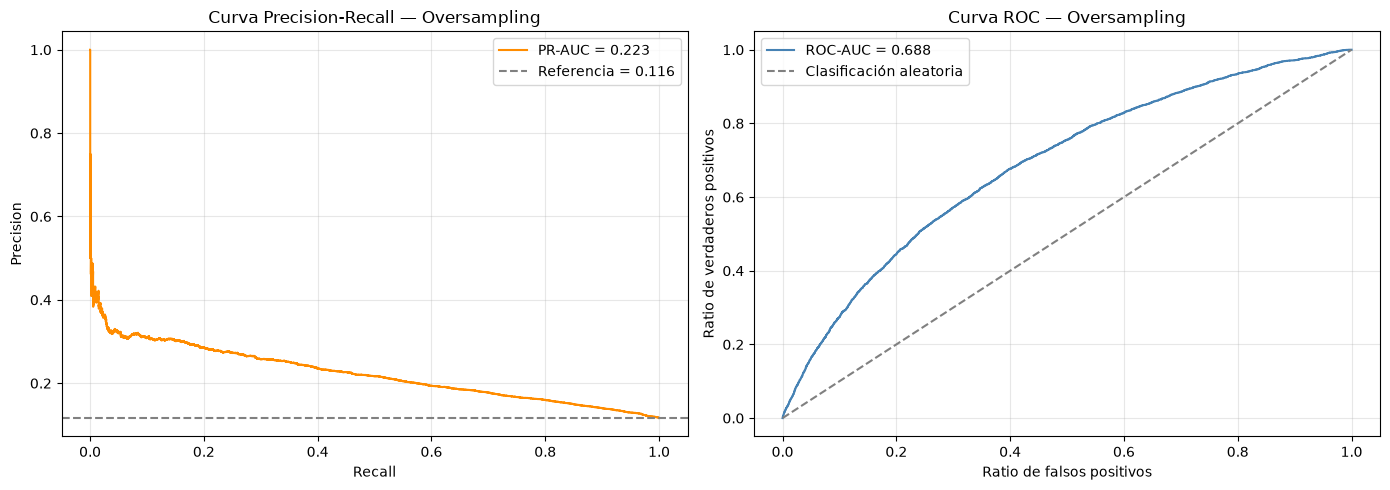

In [140]:
tabla_pr_over, tabla_roc_over = evaluar_modelo(
    modelo_over,
    X_test_scaled,
    y_test,
    nombre_modelo="Oversampling"
)

## 3. RandomUnderSampler

RandomUnderSampler es una técnica de balanceado que reduce la clase mayoritaria hasta igualar las dos clases

In [141]:
undersampler = RandomUnderSampler(random_state=42)

X_train_under, y_train_under = undersampler.fit_resample(
    X_train_scaled,
    y_train
)

print("Distribución original:")
print(pd.Series(y_train).value_counts())

print("\nDistribución después del undersampling:")
print(pd.Series(y_train_under).value_counts())

Distribución original:
Impago
0    126265
1     16619
Name: count, dtype: int64

Distribución después del undersampling:
Impago
0    16619
1    16619
Name: count, dtype: int64


In [142]:
modelo_under = LogisticRegression(
    max_iter=2000,
    random_state=42
)

modelo_under.fit(X_train_under, y_train_under)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

RESULTADOS: Undersampling

Cantidad de predicciones:
0    21094
1    14628
Name: count, dtype: int64

Matriz de confusión:
[[19654 11913]
 [ 1440  2715]]

Informe de clasificación:
              precision    recall  f1-score   support

           0       0.93      0.62      0.75     31567
           1       0.19      0.65      0.29      4155

    accuracy                           0.63     35722
   macro avg       0.56      0.64      0.52     35722
weighted avg       0.84      0.63      0.69     35722



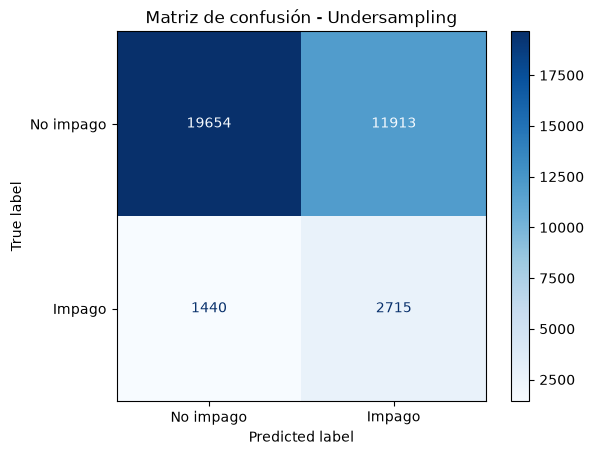

ROC-AUC: 0.688
PR-AUC: 0.223


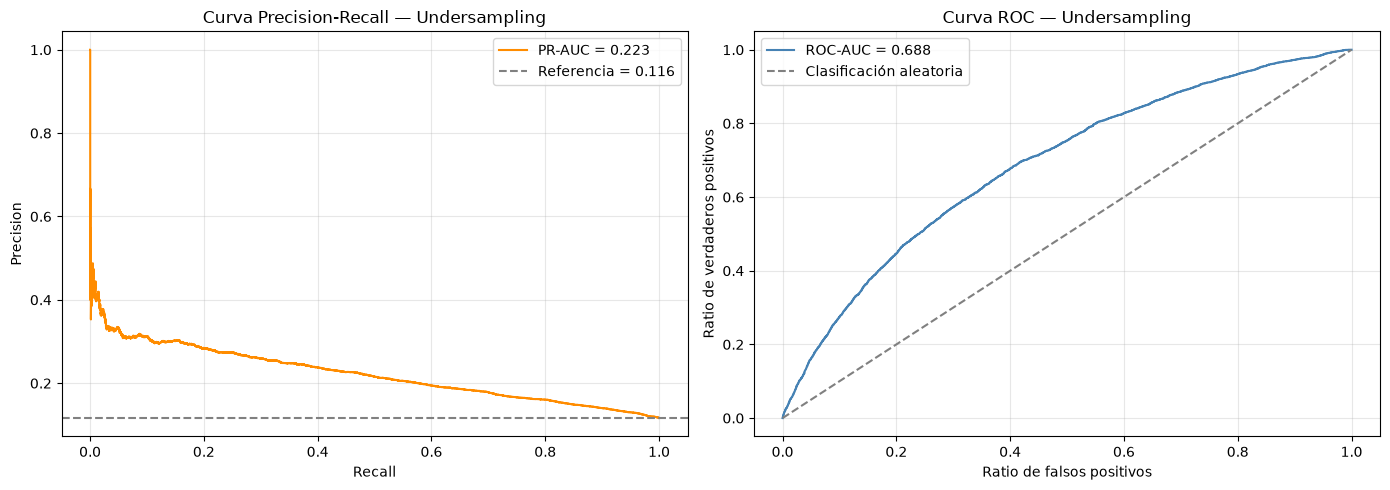

In [143]:
tabla_pr_under, tabla_roc_under = evaluar_modelo(
    modelo_under,
    X_test_scaled,
    y_test,
    nombre_modelo="Undersampling"
)

Las técnicas class_weight, oversampling y undersampling presentan resultados prácticamente equivalentes. Todas alcanzan un ROC-AUC de 0,688 y un PR-AUC de 0,223, con un recall aproximado del 65 % para la clase de impago. Ante la ausencia de diferencias predictivas relevantes, se selecciona el modelo con class_weight='balanced', ya que conserva el conjunto de entrenamiento original y evita tanto la duplicación de observaciones como la pérdida de información.

# 5. Regularización

In [148]:
modelo_cv_l1 = LogisticRegressionCV(
    Cs=np.logspace(-4, 4, 50),
    cv=5,
    penalty="l1",
    solver="saga",
    scoring="roc_auc",
    class_weight="balanced", # se añade 'class_weight' porque es el método de balanceo que se ha elegido
    max_iter=5000,
    random_state=42,
)

modelo_cv_l1.fit(
    X_train_scaled,
    y_train
)

c:\Users\izaro\RETO5\RETO5\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
c:\Users\izaro\RETO5\RETO5\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2102: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instead of penalty='l1', l1_ratios set to floats between 0 and 1 instead of penalty='elasticnet', and Cs=(np.inf,) instead of penalty=None.
  warnings.warn(
c:\Users\izaro\RETO5\RETO5\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2129: FutureWarning: The fitted attributes o

,"Cs Cs: int or list of floats, default=10Each of the values in Cs describes the inverse of regularizationstrength. If Cs is as an int, then a grid of Cs values are chosenin a logarithmic scale between 1e-4 and 1e4.Like in support vector machines, smaller values specify strongerregularization.",array([1.0000...00000000e+04])
,"cv cv: int or cross-validation generator, default=NoneThe default cross-validation generator used is Stratified K-Folds.If an integer is provided, it specifies the number of folds, `n_folds`, used.See the module :mod:`sklearn.model_selection` module for thelist of possible cross-validation objects... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"penalty penalty: {'l1', 'l2', 'elasticnet'}, default='l2'Specify the norm of the penalty:- `'l2'`: add an L2 penalty term (used by default);- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'l1'
,"scoring scoring: str or callable, default=NoneThe scoring method to use for cross-validation. Options:- str: see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)``. See :ref:`scoring_callable` for details.- `None`: :ref:`accuracy <accuracy_score>` is used... versionchanged:: 1.11 The default will change from None, i.e. accuracy, to 'neg_log_loss' in version 1.11.",'roc_auc'
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' might be slower in :class:`LogisticRegressionCV` because it does not handle warm-starting.- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) chosen and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0

In [149]:
mejor_C_l1 = modelo_cv_l1.C_[0]

print("Mejor C con regularización L1:", mejor_C_l1)

Mejor C con regularización L1: 0.004291934260128779


RESULTADOS: Regularización L1

Cantidad de predicciones:
0    21140
1    14582
Name: count, dtype: int64

Matriz de confusión:
[[19688 11879]
 [ 1452  2703]]

Informe de clasificación:
              precision    recall  f1-score   support

           0       0.93      0.62      0.75     31567
           1       0.19      0.65      0.29      4155

    accuracy                           0.63     35722
   macro avg       0.56      0.64      0.52     35722
weighted avg       0.84      0.63      0.69     35722



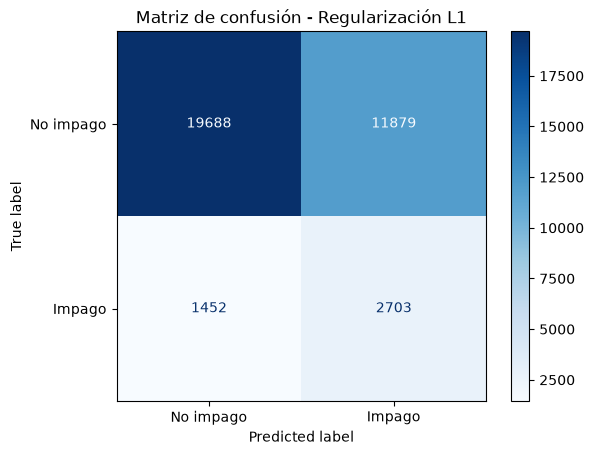

ROC-AUC: 0.688
PR-AUC: 0.223


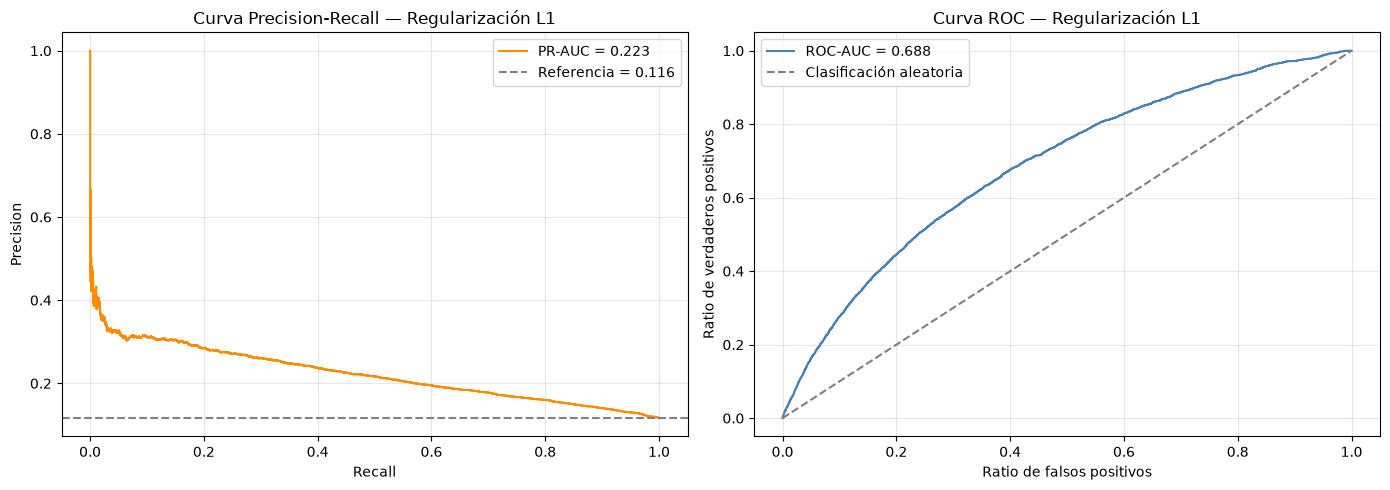

In [150]:
tabla_pr_l1, tabla_roc_l1 = evaluar_modelo(
    modelo_cv_l1,
    X_test_scaled,
    y_test,
    nombre_modelo="Regularización L1"
)